Paquetes necesarios

In [ ]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaría en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y milímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc.

In [ ]:
click = None

CENT_DIAM_MM = {
    200: 25.75,
    100: 23.25,
    50: 24.25,
    20: 22.25,
    10: 19.75,
    5: 21.25,
    2: 18.75,
    1: 16.25
}

REF = 10  # moneda de referencia (en céntimos)

px_per_mm = None

def on_mouse(event, x, y, flags, params):
    global click
    if event == cv2.EVENT_LBUTTONDOWN:
        click = (x, y)

TOL_MM = 0.6
def classify(d_px):
    d_mm = d_px / px_per_mm
    valor, diff = min(((v, abs(d_mm - mm)) for v, mm in CENT_DIAM_MM.items()),
                      key = lambda t: t[1])
    return (valor if diff < TOL_MM else None), d_mm

def segment(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (7, 7), 0)
    
    th = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 101, 6)
    
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN, k)    # quita ruido
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, k)   # rellena huecos
    
    return th

MIN_AREA = 500
MIN_CIRC = 0.6
def detect(frame):
    th = segment(frame)
    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []

    for c in contours:
        area = cv2.contourArea(c)
        
        if area < MIN_AREA:
            continue

        perimeter = cv2.arcLength(c, True)
        if perimeter == 0:
            continue

        circ = 4 * np.pi * area / perimeter**2
        if circ < MIN_CIRC:
            continue

        (cx, cy), _ = cv2.minEnclosingCircle(c)
        d_px = 2 * np.sqrt(area/np.pi)

        candidates.append((c, (int(cx), int(cy)), d_px))  # (contorno, centro, diámetro)

    return candidates


In [ ]:
vid = cv2.VideoCapture(1)

cv2.namedWindow('Monedas')
cv2.setMouseCallback('Monedas', on_mouse)

click = None
px_per_mm = None

while (True):
    ret, frame = vid.read()
    if not ret:
        break

    candidates = detect(frame)

    if click is not None:
        for c, center, d_px in candidates:
            if cv2.pointPolygonTest(c, click, False) >= 0:
                px_per_mm = d_px / CENT_DIAM_MM[REF]
                break
        click = None

    total_cent = 0

    if px_per_mm is None:
        msg = f"Haz click en una moneda de {REF/100:.2f} € para calibrar"
        cv2.putText(frame, msg, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    else:
        for c, center, d_px in candidates:
            value, d_mm = classify(d_px)

            if value is None:
                cv2.drawContours(frame, [c], -1, (0, 0, 255), 2)   # rojo: no reconocida
                continue

            total_cent += value
            cv2.drawContours(frame, [c], -1, (0, 255, 0), 2)
            cv2.putText(frame, f"{value/100:.2f}", (center[0] - 25, center[1]), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

        cv2.putText(frame, f"Total: {total_cent/100:.2f} EUR", (10, frame.shape[0] - 20), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 0), 3)
    
    cv2.imshow('Monedas', frame)
    if cv2.waitKey(20) == 27:
        break

vid.release()
cv2.destroyAllWindows()



[ WARN:0@127.585] global cap_v4l.cpp:914 open VIDEOIO(V4L2:/dev/video1): can't open camera by index
ioctl(VIDIOC_QBUF): Bad file descriptor


TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

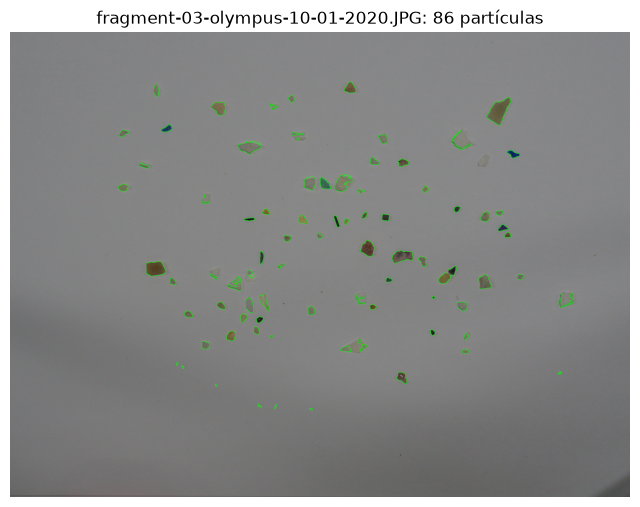

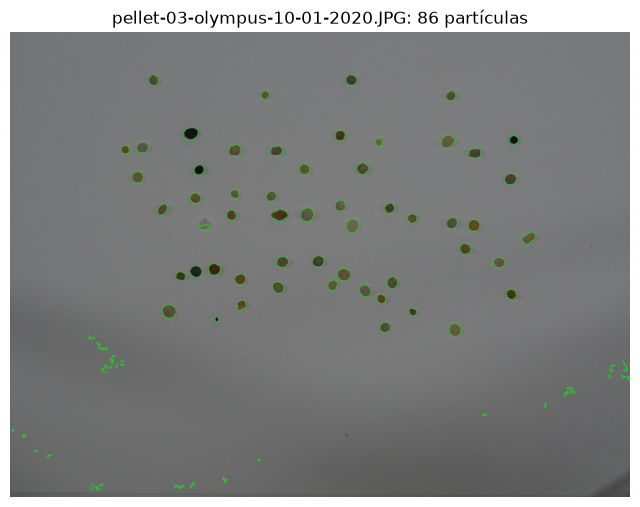

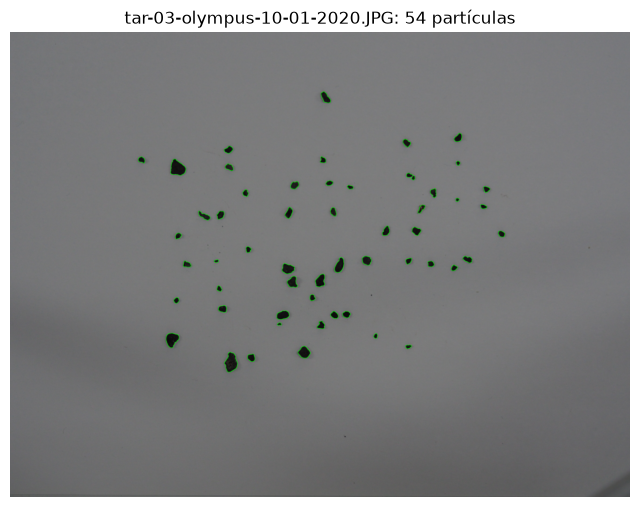

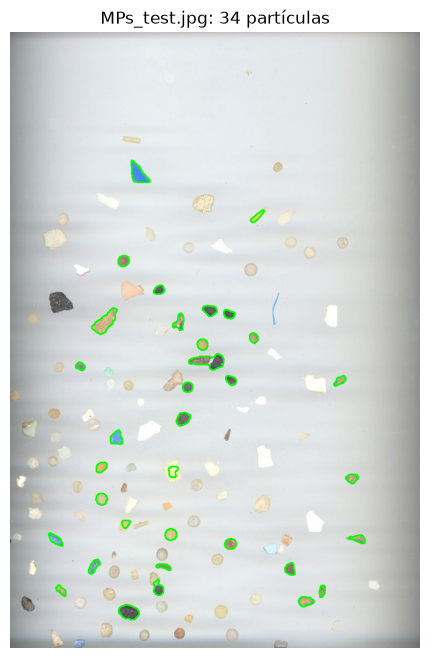

In [ ]:
MIN_AREA = 150
MAX_AREA = 20000
MIN_T = 10

TRAIN_IMAGES = {
    "FRA": "fragment-03-olympus-10-01-2020.JPG",
    "PEL": "pellet-03-olympus-10-01-2020.JPG",
    "TAR": "tar-03-olympus-10-01-2020.JPG",
}
TEST_IMAGE = "MPs_test.jpg"

def segment_particles(img_bgr):
    blur = cv2.GaussianBlur(img_bgr, (5, 5), 0)
    lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB).astype(np.float32)

    bg_color = np.median(lab.reshape(-1, 3), axis=0)

    # TODO: Explicar bien estas dos líneas
    dist = np.linalg.norm(lab - bg_color, axis=2)
    dist = np.clip(dist * 2.5, 0, 255).astype(np.uint8)

    t, _ = cv2.threshold(dist, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, th = cv2.threshold(dist, max(t, MIN_T), 255, cv2.THRESH_BINARY)

    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN, k)                # quita ruido
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, k, iterations=2) # rellena huecos

    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c for c in contours if MIN_AREA <= cv2.contourArea(c) <= MAX_AREA]
    return contours

def show_seg(path):
    img = cv2.imread(path)
    contours = segment_particles(img)
    vis = img.copy()
    cv2.drawContours(vis, contours, -1, (0, 255, 0), 2)
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.title(f"{path}: {len(contours)} partículas")
    plt.axis("off")
    plt.show()

for p in list(TRAIN_IMAGES.values()) + [TEST_IMAGE]:
    show_seg(p)

In [29]:
def particle_features(c, hsv, bg_v):
    height, width = hsv.shape[:2]
    mask = np.zeros((height, width), np.uint8)
    cv2.drawContours(mask, [c], -1, 255, -1)

    area = cv2.contourArea(c)
    perimeter = cv2.arcLength(c, True)
    circ = 4 * np.pi * area / perimeter**2

    hull_area = cv2.contourArea(cv2.convexHull(c))
    solidity = area / hull_area if hull_area > 0 else 0   # baja si es rugoso/irregular

    x, y, w, h = cv2.boundingRect(c)
    extent = area / (w * h)                 # área / área del contenedor
    aspect = min(w, h) / max(w, h)          # ancho/alto del contenedor (≤1)

    if len(c) >= 5:
        (_, axes, _) = cv2.fitEllipse(c)
        ell = min(axes) / max(axes)
    else:
        ell = 1.0

    M = cv2.moments(c)
    cx, cy = M["m10"] / M["m00"], M["m01"] / M["m00"]
    d = np.linalg.norm(c.reshape(-1, 2) - [cx, cy], axis=1)
    dratio = d.min() / d.max()              # ≈1 en círculo

    # Color: solo píxeles del interior (erosionado para evitar el borde)
    inner = cv2.erode(mask, np.ones((3, 3), np.uint8), iterations=2)
    if inner.sum() == 0:
        inner = mask
    S = hsv[..., 1][inner > 0].astype(float)
    V = hsv[..., 2][inner > 0].astype(float)

    return [circ, solidity, extent, aspect, ell, dratio,
            S.mean(), V.mean() - bg_v, V.std(), S.std()]

FEATURE_NAMES = ["circ", "solidity", "extent", "aspect", "ellipse", "dratio",
                 "S_mean", "dV_vs_bg", "V_std", "S_std"]

def image_features(img_bgr):
    cnts = segment_particles(img_bgr)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    bg_v = np.median(hsv[..., 2])
    feats = [particle_features(c, hsv, bg_v) for c in cnts]
    return cnts, np.array(feats)

FRA -> 86 partículas
PEL -> 86 partículas
TAR -> 54 partículas
       circ  solidity  extent  aspect  ellipse  dratio  S_mean  dV_vs_bg  \
clase                                                                      
FRA    0.67      0.93    0.62    0.81     0.64    0.41   36.60    -18.29   
PEL    0.84      0.98    0.74    0.92     0.85    0.72   60.04    -28.00   
TAR    0.79      0.97    0.68    0.87     0.71    0.55   26.96    -99.19   

       V_std  S_std  
clase                
FRA     5.98  10.18  
PEL     4.04  14.67  
TAR     6.01  14.81  


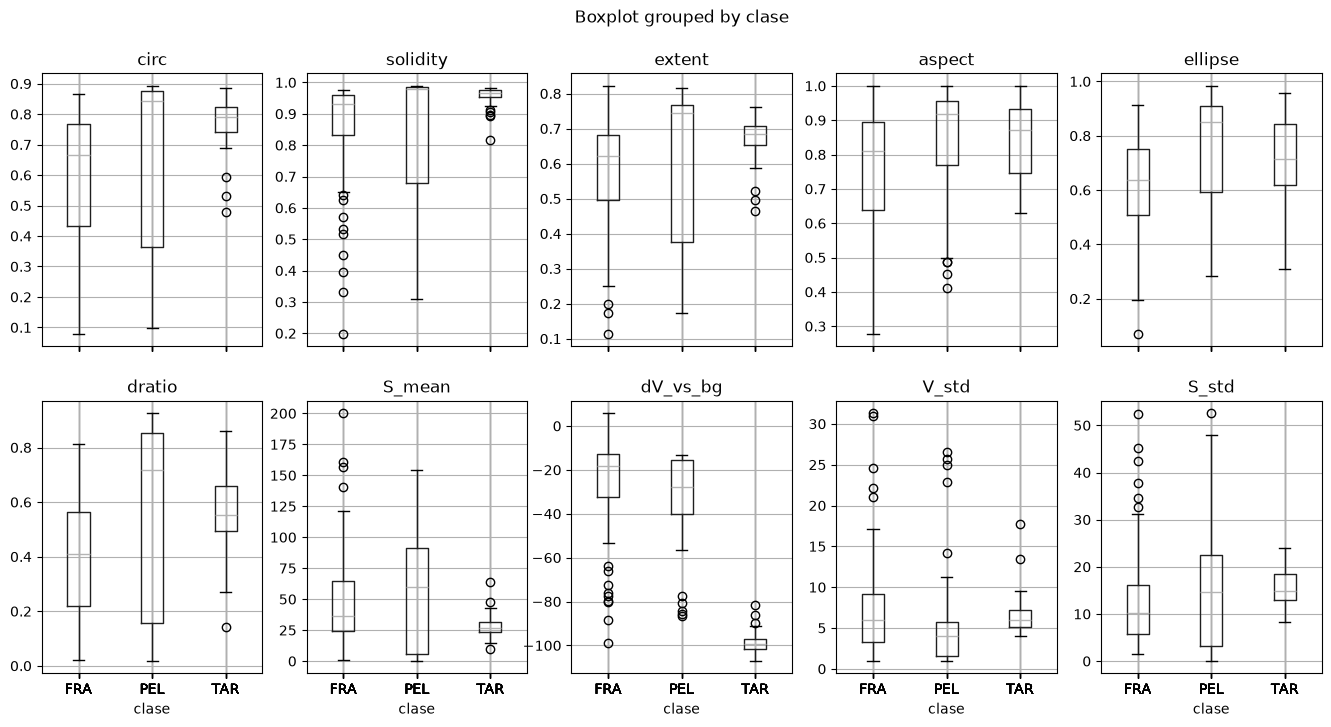

|--- dV_vs_bg <= -89.22
|   |--- V_std <= 17.77
|   |   |--- class: TAR
|   |--- V_std >  17.77
|   |   |--- class: FRA
|--- dV_vs_bg >  -89.22
|   |--- solidity <= 0.98
|   |   |--- S_mean <= 10.02
|   |   |   |--- dV_vs_bg <= -13.06
|   |   |   |   |--- class: PEL
|   |   |   |--- dV_vs_bg >  -13.06
|   |   |   |   |--- class: FRA
|   |   |--- S_mean >  10.02
|   |   |   |--- solidity <= 0.97
|   |   |   |   |--- class: FRA
|   |   |   |--- solidity >  0.97
|   |   |   |   |--- class: PEL
|   |--- solidity >  0.98
|   |   |--- class: PEL



In [34]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text


X, y = [], []
for label, path in TRAIN_IMAGES.items():
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"No se pudo leer {path}")
    _, F = image_features(img)
    print(label, "->", len(F), "partículas")
    X.append(F)
    y += [label] * len(F)
X = np.vstack(X)
y = np.array(y)

# características / clase
df = pd.DataFrame(X, columns=FEATURE_NAMES)
df["clase"] = y
print(df.groupby("clase").median().round(2))

df.boxplot(column=FEATURE_NAMES, by="clase", figsize=(16, 8), layout=(2, 5), sharey=False)
plt.show()


clf = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=0)
clf.fit(X, y)
print(export_text(clf, feature_names=FEATURE_NAMES))

Anotaciones sin contorno (fallo de segmentación): 86
Accuracy: 0.794
              precision    recall  f1-score   support

         FRA       0.76      1.00      0.86        16
         PEL       0.60      0.43      0.50         7
         TAR       1.00      0.73      0.84        11

    accuracy                           0.79        34
   macro avg       0.79      0.72      0.74        34
weighted avg       0.81      0.79      0.78        34



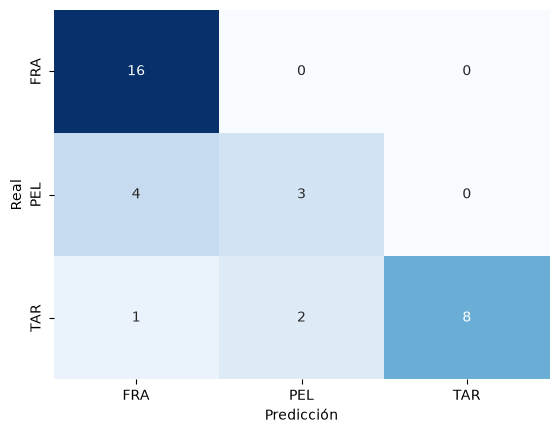

In [35]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns


img_test = cv2.imread(TEST_IMAGE)
cnts, F = image_features(img_test)

centers = []
for c in cnts:
    M = cv2.moments(c)
    centers.append((M["m10"] / M["m00"], M["m01"] / M["m00"], cv2.contourArea(c)))

y_true, y_pred, perdidas = [], [], 0
with open("MPs_test_bbs.csv", newline="") as f:
    for row in csv.DictReader(f):
        x0, y0, x1, y1 = (int(row[k]) for k in ["x_min", "y_min", "x_max", "y_max"])
        dentro = [i for i, (cx, cy, a) in enumerate(centers)
                  if x0 <= cx <= x1 and y0 <= cy <= y1]
        if not dentro:
            perdidas += 1
            continue
        i = max(dentro, key=lambda j: centers[j][2])   # el de mayor área
        y_true.append(row["label"])
        y_pred.append(clf.predict(F[i:i+1])[0])

print(f"Anotaciones sin contorno (fallo de segmentación): {perdidas}")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.3f}")
print(classification_report(y_true, y_pred, zero_division=0))

labels = ["FRA", "PEL", "TAR"]
cm = confusion_matrix(y_true, y_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()